## MircroGrad - NoteBook
#### [Source Video](https://www.youtube.com/watch?v=VMj-3S1tku0) | [Source Code](https://github.com/karpathy/micrograd)


In [ ]:
import random
import math
import numpy as np
import matplotlib.pyplot as plt
from graphviz import Digraph
%matplotlib inline

In [2]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data=data
        self._prev= set(_children)
        self._backward= lambda: None
        self._op=_op
        self.label=label
        self.grad=0.0

    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other =  other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, _children=(self, other), _op='+')

        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0

        out._backward = _backward

        return out

    def __mul__(self, other):
        other =  other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, _children=(self, other), _op='*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data ** (other-1)) * out.grad

        out._backward = _backward

        return out

    
    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        out = self * other
        return out

    def __truediv__(self, other):
        out = self * other**-1
        return out

    def __neg__(self):
        out = self * -1
        return out

    def __sub__(self, other):
        out = self + (-other)
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, _children=(self,), _op='tanh')

        def _backward():
            self.grad += (1 - (t ** 2)) * out.grad

        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward

        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [3]:
a = Value(2.0)
b = Value(4.0)
a-b


Value(data=-2.0)

In [4]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

In [5]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label='n'
# -----
o = n.tanh(); o.label='o'

o.backward()


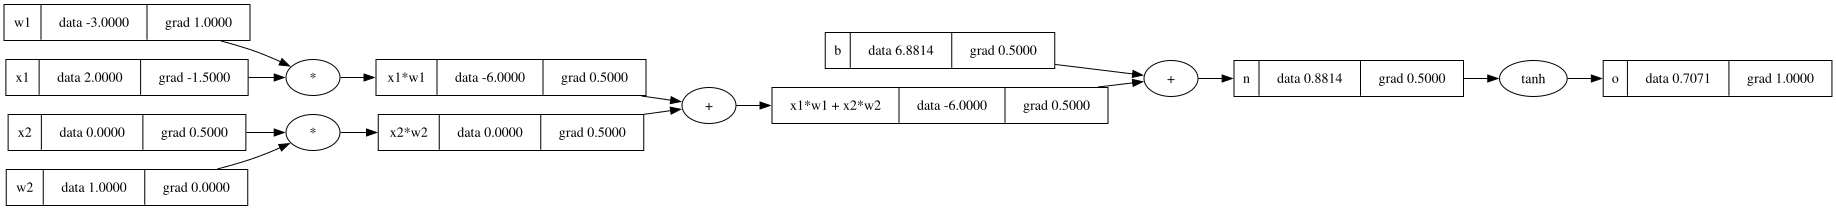

In [6]:
draw_dot(o)


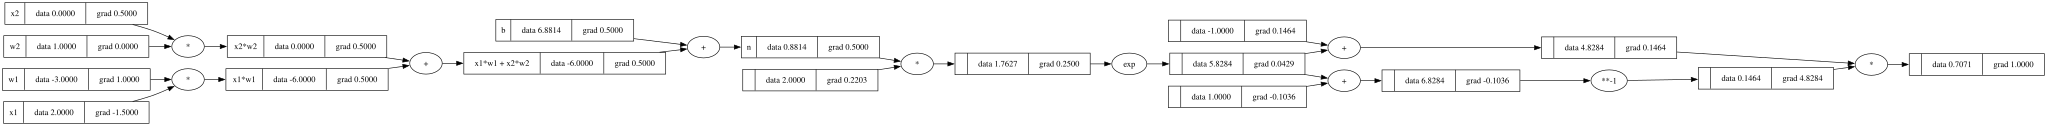

In [7]:
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1; x1w1.label='x1*w1'
x2w2 = x2 * w2; x2w2.label='x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label='n'
# -----
e = (2*n).exp()
o = (e -1 ) /  (e + 1)
# -----
o.backward()
draw_dot(o)


In [8]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b= Value(random.uniform(-1,1))

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons= [Neuron(nin) for _ in range(nout)]
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers= [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        if isinstance(x, list) and len(x) == 1:
            return x[0]
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [9]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=0.69884730888396)

In [10]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]

In [11]:

for k in range(20):

    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt,yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters():
        p.grad=0.0
    loss.backward()

    # update weighta
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)



0 4.4504297000555795
1 2.5547773071517454
2 1.1128976055288418
3 0.6820058338033291
4 0.4080772333245387
5 0.2654464284256606
6 0.19008605432606146
7 0.14528106164225882
8 0.11627987530962985
9 0.09626331203356167
10 0.08174381631835617
11 0.07079421127315631
12 0.06227712584284363
13 0.05548368364369624
14 0.04995162755025806
15 0.045367898651545446
16 0.041513593135709015
17 0.03823140718609691
18 0.03540560856099468
19 0.03294928649588406


In [12]:
ypred

[Value(data=0.9688865580775945),
 Value(data=-0.8937598068304589),
 Value(data=-0.910827277517763),
 Value(data=0.8871173744634291)]